# 空间变化三角函数体力方板：KM-PIKFNN + 解析特解

在原方板的平面应变材料及KM点力核基础上，构造具有空间变化右端项的解析验证工况。
不需要BEM/COMSOL参考数据。

## 1. 物理参数与归一化

$\Omega=[0,L]^2$，$L=1\,\mathrm m$，$E=10^6\,\mathrm{Pa}$，$\nu=0.3$。
$U_{\mathrm{ref}}=10^{-4}\,\mathrm m$，$\Sigma_{\mathrm{ref}}=EU_{\mathrm{ref}}/L=100\,\mathrm{Pa}$。
下列公式使用 $\xi=x/L,\eta=y/L,z=\xi+i\eta$ 及
$\mu^*=1/[2(1+\nu)],\lambda_{\mathrm L}^*=\nu/[(1+\nu)(1-2\nu)]$。
$\lambda_{\mathrm L}$ 为Lamé常数。

## 2. 空间变化体力与特解

取 $\beta=0.08$，解析特解为
$$\mathbf u_p^*=\beta
\begin{pmatrix}\cos(\pi\xi)\sin(2\pi\eta)\\2\sin(\pi\xi)\cos(2\pi\eta)\end{pmatrix}.$$
它由标量函数 $\sin(\pi\xi)\sin(2\pi\eta)$ 的梯度生成。
体力由平衡方程确定：
$$\mathbf f^*=5\pi^2(\lambda_{\mathrm L}^*+2\mu^*)\mathbf u_p^*,$$
$$\mathbf f(x,y)=A
\begin{pmatrix}\cos(\pi x/L)\sin(2\pi y/L)\\2\sin(\pi x/L)\cos(2\pi y/L)\end{pmatrix},\quad
A=5\pi^2\beta(\lambda_{\mathrm L}^*+2\mu^*)\frac{EU_{\mathrm{ref}}}{L^2}.$$
默认 $A\approx531.4402\,\mathrm{N/m^3}$，两个分量均随空间坐标变化并改变符号。

令 $S=\sin(\pi\xi)\sin(2\pi\eta),C=\cos(\pi\xi)\cos(2\pi\eta)$，特解应力为
$$\sigma_{xx,p}^*=-\beta\pi(5\lambda_{\mathrm L}^*+2\mu^*)S,\quad
\sigma_{yy,p}^*=-\beta\pi(5\lambda_{\mathrm L}^*+8\mu^*)S,\quad
\sigma_{xy,p}^*=4\beta\pi\mu^*C.$$
物理位移与应力分别为 $U_{\mathrm{ref}}\mathbf u_p^*$ 和 $\Sigma_{\mathrm{ref}}\boldsymbol\sigma_p^*$。

## 3. 非零齐次场与总解析解

令 $w=z-(1+i)/2$，参考齐次复势为
$$\phi_h^*(z)=(0.12+0.04i)w^3+0.05z,\qquad\psi_h^*(z)=(-0.06+0.03i)w^2.$$
经KM关系生成 $\mathbf u_h^*,\boldsymbol\sigma_h^*$，总解析解为
$$\mathbf u_{\mathrm{exact}}^*=\mathbf u_p^*+\mathbf u_h^*,\qquad
\boldsymbol\sigma_{\mathrm{exact}}^*=\boldsymbol\sigma_p^*+\boldsymbol\sigma_h^*.$$
参考齐次场只用于参考解及边界数据，**不直接放入网络基函数**。网络仍需用KM点力核及常数/一次势项逼近该非零齐次场。

## 4. 边界条件与训练

- 顶、底边给定总解析位移；左、右边给定总解析面力 $\boldsymbol\sigma_{\mathrm{exact}}\mathbf n$。
- 训练扣除特解对应的边界位移/面力，求KM齐次场，再叠加特解恢复总场。
- 没有内部PDE训练配点；内部解析解只用于误差诊断。
- 默认96个源点、400个边界训练点、201个可训练实参数；独立边界检查点用于选择运行。
- 源点比例 $1.03<\alpha<1.65$；初值为1.10、1.20、1.30。
- SVD暖启动 + L-BFGS联合优化；`warm_start=False`为系数全零冷启动；`adaptive_sources=False`固定源点。
- 记录一次L-BFGS外层调用的历史；总耗时包含初始化、矩阵组装及训练诊断。
- float64/complex128，先检查CUDA复数运算及反向传播；缺少NVRTC库时自动回退CPU。可设置`device="cpu"`直接使用CPU；依赖`numpy scipy torch matplotlib`。
- `save_outputs=True`保存全场、空间变化体力、误差、源点及训练曲线。

这验证的是**具有已知三角函数特解的空间变化体力问题**，不代表已实现任意未知特解的体力处理。


In [1]:
import numpy as np
import torch
from torch import nn
from scipy.linalg import lstsq
import matplotlib.pyplot as plt
from pathlib import Path
import csv
import time

# Physical fields: x=L*x*, u=U_ref*u*, sigma=Sigma_ref*sigma*.
cfg = dict(L=1.0, E_real=1.0e6, nu=0.3, U_ref=1.0e-4,
           n_source_per_side=24, n_boundary_per_side=100,
           alpha_initials=[1.10, 1.20, 1.30], alpha_min=1.03, alpha_max=1.65,
           adaptive_sources=True, warm_start=True, lbfgs_epochs=35,
           lbfgs_max_iter=20, lr=1.0, regularization=1.0e-14,
           svd_cutoff=1.0e-12, print_every=5, nx_plot=101,
           device='auto', cuda_fallback_to_cpu=True, save_outputs=False, output_dir='square_body_force_results')
dtype = torch.float64
# Windows NVRTC may not find its builtins DLL even when a GPU is visible.
# Keep directory handles alive for the lifetime of the notebook kernel.
import os
import sys
_dll_directory_handles = []
if os.name == 'nt' and hasattr(os, 'add_dll_directory'):
    cuda_version = torch.version.cuda or ''
    suffix = cuda_version.replace('.', '')
    builtin_name = f'nvrtc-builtins64_{suffix}.dll'
    candidates = [Path(torch.__file__).resolve().parent/'lib',
                  Path(sys.prefix)/'Library'/'bin']
    if os.environ.get('CUDA_PATH'):
        candidates.append(Path(os.environ['CUDA_PATH'])/'bin')
    for directory in candidates:
        if (directory/builtin_name).is_file():
            _dll_directory_handles.append(os.add_dll_directory(str(directory)))

def _cuda_complex_probe(selected_device):
    # Exercise the same complex128 operations and backward pass used by KM.
    real = torch.linspace(0.2, 1.2, 1024, dtype=torch.float64,
                          device=selected_device, requires_grad=True)
    q = torch.complex(real, 0.3*real+0.1)
    value = (torch.angle(-q)+torch.abs(q)+torch.log(torch.abs(q))
             +torch.exp(q).real+(1/q).real+(q.conj()**3).real).sum()
    value.backward()
    torch.cuda.synchronize(selected_device)

def select_device(requested='auto', fallback=True, probe=None):
    selected = torch.device(('cuda' if torch.cuda.is_available() else 'cpu')
                            if requested == 'auto' else requested)
    if selected.type == 'cuda':
        try:
            (_cuda_complex_probe if probe is None else probe)(selected)
        except (RuntimeError, OSError, AssertionError) as error:
            if not fallback:
                raise
            # Do not print the thousands of lines of generated CUDA source.
            lines = str(error).strip().splitlines()
            reason = next((line.strip() for line in lines
                           if 'nvrtc:' in line or 'failed to open' in line),
                          lines[-1] if lines else type(error).__name__)
            print('CUDA complex-operation check failed:', reason)
            print('Switching this run to CPU. Set cfg["device"]="cpu" to skip the CUDA check.')
            selected = torch.device('cpu')
    return selected

device = select_device(cfg['device'], cfg['cuda_fallback_to_cpu'])
if device.type == 'cpu':
    torch.set_num_threads(min(4, torch.get_num_threads()))
np.random.seed(42)
torch.manual_seed(42)
L, E_real, nu, U_ref = (cfg[k] for k in ('L', 'E_real', 'nu', 'U_ref'))
Sigma_ref = E_real*U_ref/L
F_ref = Sigma_ref/L
mu = 1.0/(2*(1+nu))  # normalized plane-strain material
lam = nu/((1+nu)*(1-2*nu))
kappa = 3-4*nu
beta = 0.08
force_amplitude = 5*np.pi**2*beta*(lam+2*mu)*F_ref
print('Device:', device, '| precision: float64 | plane strain')
print('Variable trigonometric body force amplitudes [N/m^3]:', force_amplitude, 2*force_amplitude)



CUDA complex-operation check failed: nvrtc: error: failed to open nvrtc-builtins64_118.dll.
Switching this run to CPU. Set cfg["device"]="cpu" to skip the CUDA check.
Device: cpu | precision: float64 | plane strain
Variable trigonometric body force amplitudes [N/m^3]: 531.4402369817346 1062.8804739634693


## 3. KM齐次核、边界修正、暖启动与源点联合优化
修改第一段代码中的`cfg`，然后运行下面单元格。

In [2]:
def tensor(x):
    is_complex = x.is_complex() if isinstance(x, torch.Tensor) else np.iscomplexobj(x)
    return torch.as_tensor(x, dtype=torch.complex128 if is_complex else dtype, device=device)

def km_reconstruct(z, phi, psi, dphi, ddphi, dpsi):
    uc = (kappa*phi-z*torch.conj(dphi)-torch.conj(psi))/(2*mu)
    dev = torch.conj(z)*ddphi+dpsi
    return torch.stack((uc.real, uc.imag, 2*dphi.real-dev.real,
                        2*dphi.real+dev.real, dev.imag), dim=-1)

def particular_fields(z):
    # Gradient-generated trigonometric particular solution (plane strain).
    x, y = z.real, z.imag
    sx, cx = torch.sin(torch.pi*x), torch.cos(torch.pi*x)
    sy, cy = torch.sin(2*torch.pi*y), torch.cos(2*torch.pi*y)
    up = beta*cx*sy
    vp = 2*beta*sx*cy
    sxx = -beta*torch.pi*(5*lam+2*mu)*sx*sy
    syy = -beta*torch.pi*(5*lam+8*mu)*sx*sy
    sxy = 4*beta*torch.pi*mu*cx*cy
    return torch.stack((up, vp, sxx, syy, sxy), dim=-1)

def body_force_fields(z):
    # Delta(u_p*)=-5*pi^2*u_p*, and u_p* is irrotational.
    # Thus f*=-mu*Delta(u_p*)-(lambda+mu)*grad(div(u_p*))
    #        =5*pi^2*(lambda+2*mu)*u_p*.
    return 5*torch.pi**2*(lam+2*mu)*particular_fields(z)[:, :2]

def exact_homogeneous_fields(z):
    # Nonzero cubic/quadratic analytic potentials, used ONLY for reference
    # and boundary data. They are NOT inserted as network basis functions.
    w = z-(0.5+0.5j)
    C, D, T = 0.12+0.04j, -0.06+0.03j, 0.05
    phi, psi = C*w**3+T*z, D*w**2
    return km_reconstruct(z, phi, psi, 3*C*w*w+T, 6*C*w, 2*D*w)

def exact_fields(z):
    return particular_fields(z)+exact_homogeneous_fields(z)

def von_mises(q):
    sx, sy, t = q[..., 2], q[..., 3], q[..., 4]
    sz = nu*(sx+sy)
    return torch.sqrt(torch.clamp(((sx-sy)**2+(sy-sz)**2+(sz-sx)**2)/2+3*t*t, min=0))

def boundary_points(n, held_out=False):
    # Training and independent validation points do not coincide.
    t = (np.arange(n)+(0.5 if held_out else 0.25))/n
    return {key: tensor(z) for key, z in dict(bottom=t+0j, top=t+1j,
            left=1j*t, right=1+1j*t).items()}

train_points = boundary_points(cfg['n_boundary_per_side'])
check_points = boundary_points(2*cfg['n_boundary_per_side']+1, True)

def boundary_targets(points):
    # Start from TOTAL exact boundary data, then subtract the particular
    # displacement/traction. Dirichlet top/bottom; traction left/right.
    targets = {}
    for key, z in points.items():
        columns = (0, 1) if key in ('bottom', 'top') else (2, 4)
        targets[key] = (exact_fields(z)-particular_fields(z))[:, list(columns)].detach()
    # On vertical sides, t=n_x*(sigma_xx,sigma_xy); using the same sign
    # for prediction and target makes these residuals equivalent to traction.
    return targets

train_targets, check_targets = boundary_targets(train_points), boundary_targets(check_points)

class KMBodyForceNet(nn.Module):
    def __init__(self, alpha0):
        super().__init__()
        n = cfg['n_source_per_side']
        t = torch.linspace(-0.5, 0.5, n+2, dtype=dtype, device=device)[1:-1]
        base = torch.cat((t-0.5j, 0.5+1j*t, t.flip(0)+0.5j, -0.5+1j*t.flip(0)))
        self.register_buffer('base', base)
        self.register_buffer('branch', torch.angle(-base))
        self.ns = len(base)
        self.register_buffer('column_scale', torch.ones(2*self.ns+8, dtype=dtype, device=device))
        fraction = (alpha0-cfg['alpha_min'])/(cfg['alpha_max']-cfg['alpha_min'])
        self.eta = nn.Parameter(tensor(np.log(fraction/(1-fraction))),
                                requires_grad=cfg['adaptive_sources'])
        self.theta = nn.Parameter(torch.zeros(2*self.ns+8, dtype=dtype, device=device))

    def alpha(self):
        return cfg['alpha_min']+(cfg['alpha_max']-cfg['alpha_min'])*torch.sigmoid(self.eta)

    def sources(self):
        return (0.5+0.5j)+self.alpha()*self.base

    def fields(self, z, raw_coefficients=None):
        c = self.theta/self.column_scale if raw_coefficients is None else raw_coefficients
        s = self.sources()
        q = z.reshape(-1, 1)-s.reshape(1, -1)
        rot = q*torch.exp(-1j*self.branch)
        # The branch cut points away from the physical square for all alpha>1.
        logq = torch.log(torch.abs(q))+1j*(torch.atan2(rot.imag, rot.real)+self.branch)
        P = torch.complex(c[:self.ns], c[self.ns:2*self.ns])/np.sqrt(self.ns)
        cf = 1/(2*np.pi*(kappa+1))
        phi = -cf*(logq@P)
        dphi = -cf*((1/q)@P)
        ddphi = cf*((1/q**2)@P)
        psi = cf*(kappa*(logq@P.conj())+(1/q)@(P*s.conj()))
        dpsi = cf*(kappa*((1/q)@P.conj())-(1/q**2)@(P*s.conj()))
        a = c[2*self.ns:].reshape(4, 2)
        a = torch.complex(a[:, 0], a[:, 1])
        phi = phi+a[0]+a[1]*z
        psi = psi+a[2]+a[3]*z
        dphi, dpsi = dphi+a[1], dpsi+a[3]
        return km_reconstruct(z, phi, psi, dphi, ddphi, dpsi)

    def total_fields(self, z):
        return self.fields(z)+particular_fields(z)

def residuals(model, points, targets, coefficients=None):
    items = []
    for key, z in points.items():
        columns = (0, 1) if key in ('bottom', 'top') else (2, 4)
        items.append((model.fields(z, coefficients)[:, list(columns)]-targets[key]).reshape(-1)
                     /np.sqrt(len(z)))
    return torch.cat(items)

def edge_losses(model, points=train_points, targets=train_targets):
    r = residuals(model, points, targets)
    # Each edge loss is mean squared Euclidean residual of its two components.
    lengths = [2*len(z) for z in points.values()]
    return {key: chunk.square().sum() for key, chunk in zip(points, r.split(lengths))}

def boundary_loss(model, points=train_points, targets=train_targets):
    return residuals(model, points, targets).square().sum()

def initialize(model):
    t0 = time.perf_counter()
    with torch.no_grad():
        n = len(model.theta)
        zero = torch.zeros(n, dtype=dtype, device=device)
        r0 = residuals(model, train_points, train_targets, zero)
        # Column scaling is also used for cold starts, so the two options
        # differ only in coefficient initialization.
        cols = []
        for j in range(n):
            unit = zero.clone(); unit[j] = 1
            cols.append((residuals(model, train_points, train_targets, unit)-r0).cpu().numpy())
        A = np.column_stack(cols)
        scale = np.maximum(np.linalg.norm(A, axis=0), 1e-12)
        model.column_scale.copy_(tensor(scale))
        if cfg['warm_start']:
            sol, _, rank, singular = lstsq(A/scale, -r0.cpu().numpy(),
                                          cond=cfg['svd_cutoff'], lapack_driver='gelsd')
            model.theta.copy_(tensor(sol))
            print(f'  SVD warm start: rank={rank}/{n}')
        else:
            model.theta.zero_()  # coefficient cold start; no least-squares solve
            print('  Cold start: all kernel and affine coefficients are zero')
    return time.perf_counter()-t0

def objective(model):
    return boundary_loss(model)+cfg['regularization']*model.theta.square().mean()

def train_one(alpha0):
    t0 = time.perf_counter()
    model = KMBodyForceNet(alpha0).to(device)
    init_time = initialize(model)
    history = []
    def record(epoch):
        with torch.no_grad():
            edges = edge_losses(model)
            q = model.total_fields(monitor_z)
            displacement_error = torch.linalg.vector_norm(q[:, :2]-monitor_ref[:, :2])/torch.linalg.vector_norm(monitor_ref[:, :2])
            stress_error = torch.linalg.vector_norm(q[:, 2:]-monitor_ref[:, 2:])/torch.linalg.vector_norm(monitor_ref[:, 2:])
            row = dict(iteration=epoch, alpha=model.alpha().item(),
                       boundary_loss=sum(v.item() for v in edges.values()),
                       objective=objective(model).item(),
                       held_out_loss=boundary_loss(model, check_points, check_targets).item(),
                       displacement_L2=displacement_error.item(), stress_L2=stress_error.item())
            row.update({f'loss_{k}': v.item() for k, v in edges.items()})
            history.append(row)
        return row
    row = record(0)
    best = row['objective']; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
    opt = torch.optim.LBFGS([p for p in model.parameters() if p.requires_grad],
            lr=cfg['lr'], max_iter=cfg['lbfgs_max_iter'], history_size=100,
            tolerance_grad=1e-12, tolerance_change=1e-15, line_search_fn='strong_wolfe')
    print(f'alpha0={alpha0:.2f}; Ns={model.ns}; parameters={sum(p.numel() for p in model.parameters() if p.requires_grad)}')
    for epoch in range(1, cfg['lbfgs_epochs']+1):
        def closure():
            opt.zero_grad()
            loss = objective(model)
            loss.backward()
            return loss
        opt.step(closure)
        row = record(epoch)
        if row['objective'] < best:
            best = row['objective']; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        if epoch == 1 or epoch % cfg['print_every'] == 0 or epoch == cfg['lbfgs_epochs']:
            print(f"  L-BFGS {epoch:3d}: alpha={row['alpha']:.6f}, boundary={row['boundary_loss']:.3e}, "
                  f"held-out={row['held_out_loss']:.3e}, L2(u)={row['displacement_L2']:.3e}, L2(stress)={row['stress_L2']:.3e}")
    model.load_state_dict(best_state)
    if device.type == 'cuda': torch.cuda.synchronize()
    return dict(model=model, history=history, alpha0=alpha0,
                elapsed=time.perf_counter()-t0, initialization_time=init_time,
                check_loss=boundary_loss(model, check_points, check_targets).item())

t = np.linspace(0.02, 0.98, 31)
mx, my = np.meshgrid(t, t)
monitor_z = tensor((mx+1j*my).ravel())
monitor_ref = exact_fields(monitor_z).detach()
runs = [train_one(alpha0) for alpha0 in cfg['alpha_initials']]
# Choose by independent boundary residual, NEVER by interior reference error.
best_run = min(runs, key=lambda r: r['check_loss'])
model = best_run['model']
print('Selected by independent boundary loss:', best_run['alpha0'],
      '->', model.alpha().item(), '| total elapsed includes initialization:', best_run['elapsed'])


  SVD warm start: rank=198/200
alpha0=1.10; Ns=96; parameters=201
  L-BFGS   1: alpha=1.113196, boundary=2.173e-06, held-out=2.249e-06, L2(u)=7.788e-04, L2(stress)=1.848e-03
  L-BFGS   5: alpha=1.173261, boundary=6.161e-08, held-out=6.832e-08, L2(u)=1.971e-04, L2(stress)=6.052e-04
  L-BFGS  10: alpha=1.197641, boundary=1.448e-08, held-out=1.527e-08, L2(u)=1.025e-04, L2(stress)=2.981e-04
  L-BFGS  15: alpha=1.203630, boundary=9.480e-09, held-out=1.016e-08, L2(u)=8.102e-05, L2(stress)=2.501e-04
  L-BFGS  20: alpha=1.203809, boundary=9.202e-09, held-out=9.893e-09, L2(u)=7.900e-05, L2(stress)=2.468e-04
  L-BFGS  25: alpha=1.203969, boundary=9.002e-09, held-out=9.691e-09, L2(u)=7.753e-05, L2(stress)=2.442e-04
  L-BFGS  30: alpha=1.204111, boundary=8.836e-09, held-out=9.520e-09, L2(u)=7.625e-05, L2(stress)=2.421e-04
  L-BFGS  35: alpha=1.204241, boundary=8.690e-09, held-out=9.369e-09, L2(u)=7.511e-05, L2(stress)=2.402e-04
  SVD warm start: rank=198/200
alpha0=1.20; Ns=96; parameters=201
  L-

## 4. 独立物理恒等式及误差验证
平衡残差含体力项，并同时核对位移导数与应力本构关系。这些检查不参与训练。

In [3]:

pos = tensor(np.random.uniform(0.1, 0.9, (30, 2))).requires_grad_(True)
zp = torch.complex(pos[:, 0], pos[:, 1])
qref = exact_fields(zp)
gr = [torch.autograd.grad(qref[:, i].sum(), pos, retain_graph=True)[0] for i in (2,3,4)]
fr = body_force_fields(zp)
eq_ref = torch.stack((gr[0][:, 0]+gr[2][:, 1]+fr[:, 0],
                      gr[2][:, 0]+gr[1][:, 1]+fr[:, 1]), dim=-1)
print('Exact-reference equilibrium max residual (normalized):', eq_ref.abs().max().item())
assert eq_ref.abs().max().item() < 1e-10
# Independent interior verification (diagnostic only, not a training residual).
xy = tensor(np.random.uniform(0.1, 0.9, (30, 2))).requires_grad_(True)
z_test = torch.complex(xy[:, 0], xy[:, 1])
q_test = model.total_fields(z_test)
def spatial_gradient(value):
    return torch.autograd.grad(value.sum(), xy, create_graph=True)[0]
sxg, syg, tg = (spatial_gradient(q_test[:, i]) for i in (2, 3, 4))
f_test = body_force_fields(z_test)
eq = torch.stack((sxg[:, 0]+tg[:, 1]+f_test[:, 0],
                  tg[:, 0]+syg[:, 1]+f_test[:, 1]), dim=-1)
ug, vg = spatial_gradient(q_test[:, 0]), spatial_gradient(q_test[:, 1])
sx_hooke = (lam+2*mu)*ug[:, 0]+lam*vg[:, 1]
sy_hooke = lam*ug[:, 0]+(lam+2*mu)*vg[:, 1]
t_hooke = mu*(ug[:, 1]+vg[:, 0])
constitutive = q_test[:, 2:]-torch.stack((sx_hooke, sy_hooke, t_hooke), dim=-1)
equilibrium_max = eq.abs().max().item()
constitutive_max = constitutive.abs().max().item()
print(f'Independent equilibrium max residual (normalized): {equilibrium_max:.3e}')
print(f'Independent constitutive max residual (normalized): {constitutive_max:.3e}')
assert equilibrium_max < 1e-8 and constitutive_max < 1e-8, 'Physical identity check failed'

def batched_predict(z, batch_size=2048):
    with torch.no_grad():
        return torch.cat([model.total_fields(c) for c in z.split(batch_size)]).cpu().numpy()

axis = np.linspace(0, 1, cfg['nx_plot'])
X, Y = np.meshgrid(axis, axis)
plot_z = tensor((X+1j*Y).ravel())
prediction = batched_predict(plot_z)
with torch.no_grad():
    reference = exact_fields(plot_z).cpu().numpy()
    vm_pred = von_mises(tensor(prediction)).cpu().numpy()
    vm_ref = von_mises(tensor(reference)).cpu().numpy()
prediction = np.column_stack((prediction, vm_pred))
reference = np.column_stack((reference, vm_ref))
physical_scales = np.array([U_ref, U_ref, Sigma_ref, Sigma_ref, Sigma_ref, Sigma_ref])
prediction_real, reference_real = prediction*physical_scales, reference*physical_scales
quantities = ('ux', 'uy', 'sxx', 'syy', 'sxy', 'von_mises')
labels = (r'$u_x$ (m)', r'$u_y$ (m)', r'$\sigma_{xx}$ (Pa)',
          r'$\sigma_{yy}$ (Pa)', r'$\sigma_{xy}$ (Pa)', r'$\sigma_{\mathrm{vM}}$ (Pa)')
error_table = []
for i, name in enumerate(quantities):
    relative = np.linalg.norm(prediction[:, i]-reference[:, i])/np.linalg.norm(reference[:, i])
    maximum = np.max(abs(prediction[:, i]-reference[:, i]))/np.max(abs(reference[:, i]))
    error_table.append(dict(quantity=name, relative_L2=relative, max_normalized_error=maximum))
    print(f'{name:10s}: relative L2={relative:.6e}, max normalized error={maximum:.6e}')
print('Each held-out boundary loss:', {k: v.item() for k, v in edge_losses(model, check_points, check_targets).items()})



Exact-reference equilibrium max residual (normalized): 1.7763568394002505e-15
Independent equilibrium max residual (normalized): 1.776e-15
Independent constitutive max residual (normalized): 4.996e-16
ux        : relative L2=1.793349e-08, max normalized error=1.429233e-07
uy        : relative L2=8.063779e-09, max normalized error=8.551286e-08
sxx       : relative L2=1.491728e-07, max normalized error=3.600541e-06
syy       : relative L2=7.322546e-08, max normalized error=1.317417e-06
sxy       : relative L2=2.290437e-07, max normalized error=2.752414e-06
von_mises : relative L2=1.471368e-07, max normalized error=2.513425e-06
Each held-out boundary loss: {'bottom': 1.477158685677638e-17, 'top': 1.064876826791705e-16, 'left': 3.086373537541185e-15, 'right': 1.81893238180394e-15}


## 5. 六物理量、源点与优化曲线
每个物理量比较解析解、预测和归一化误差；颜色条为平端且与云图等高。

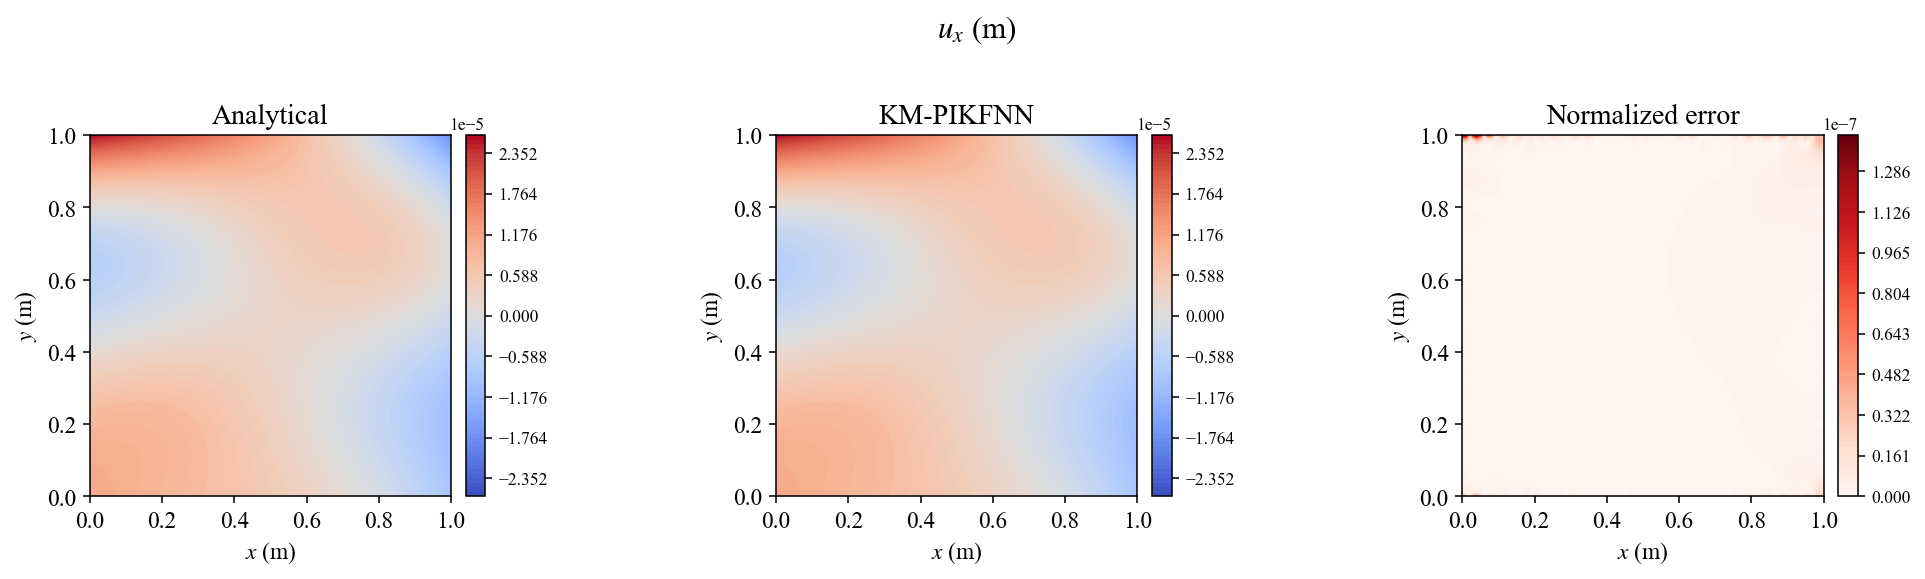

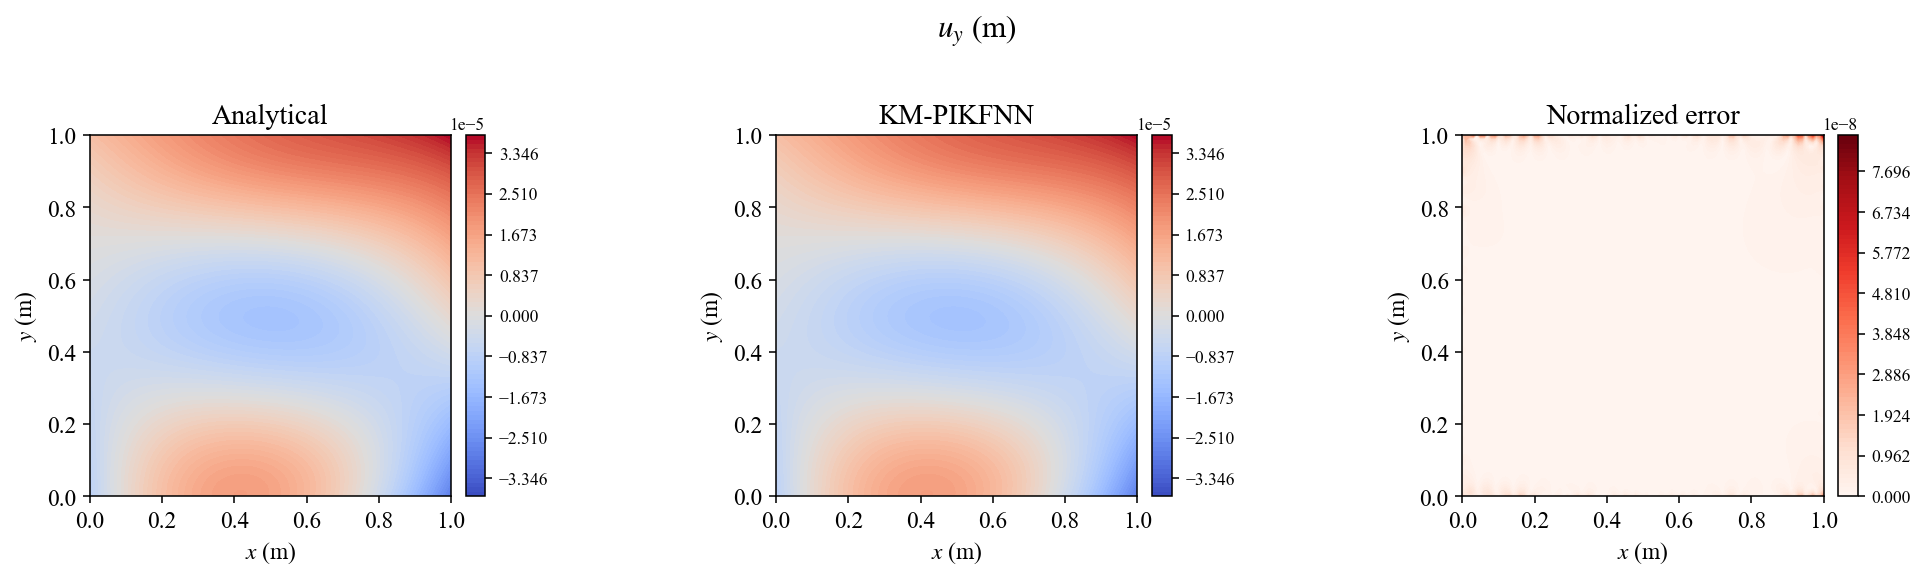

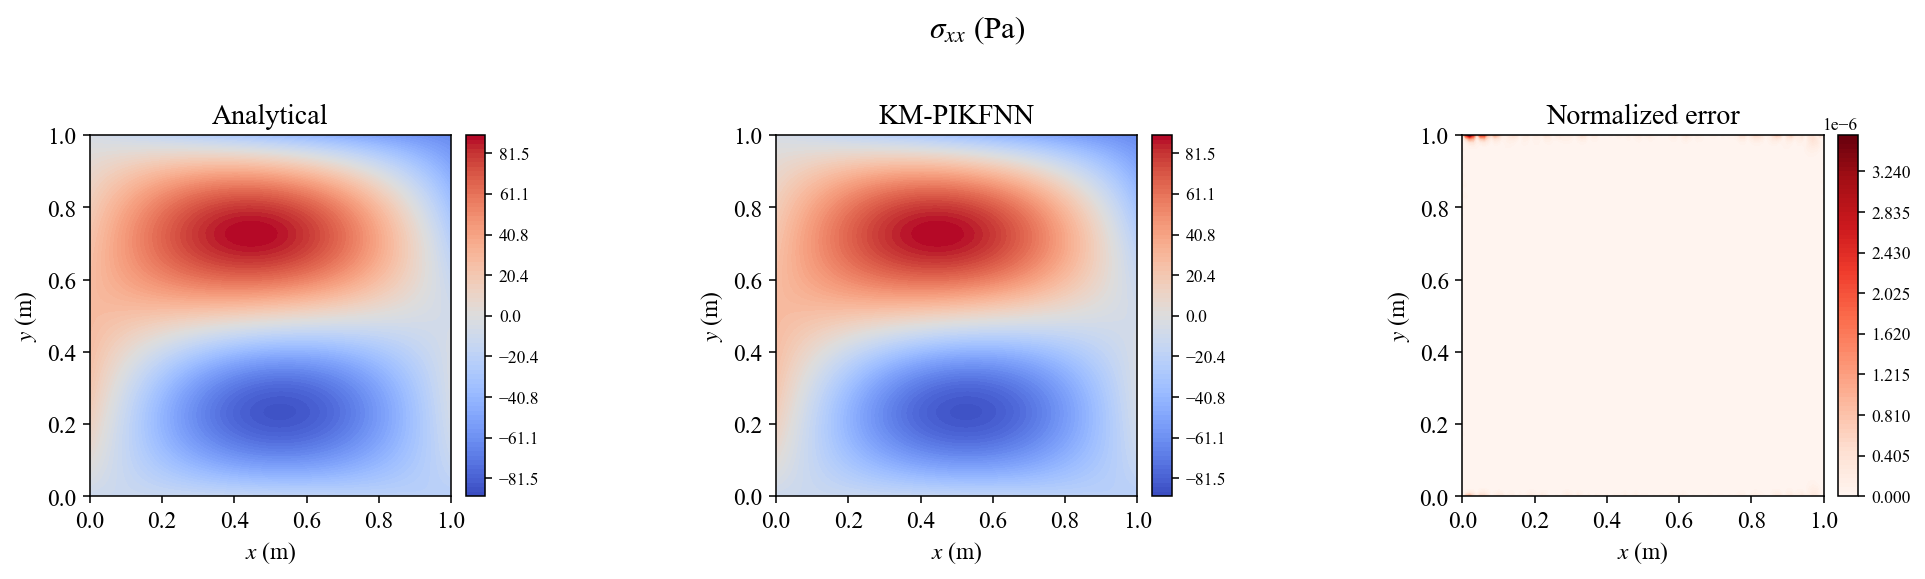

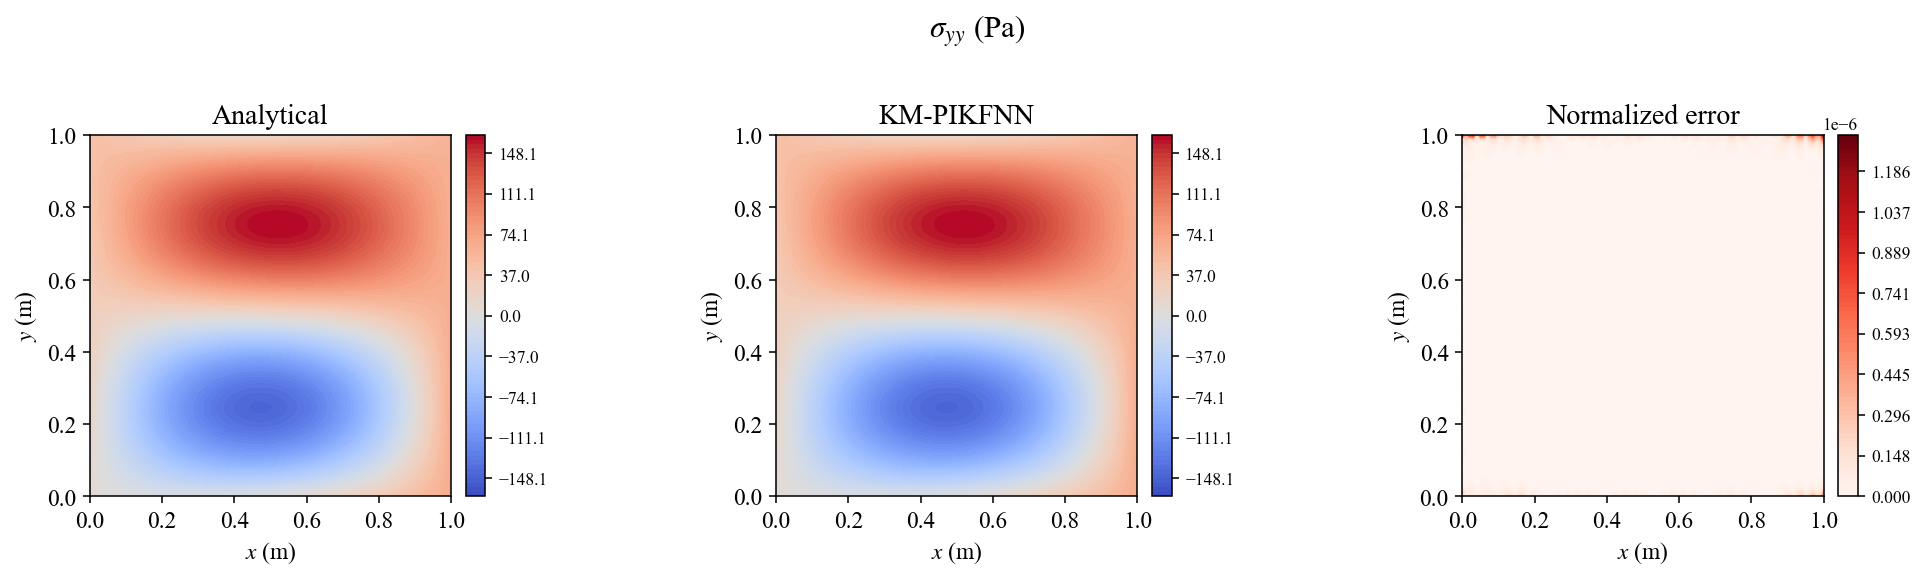

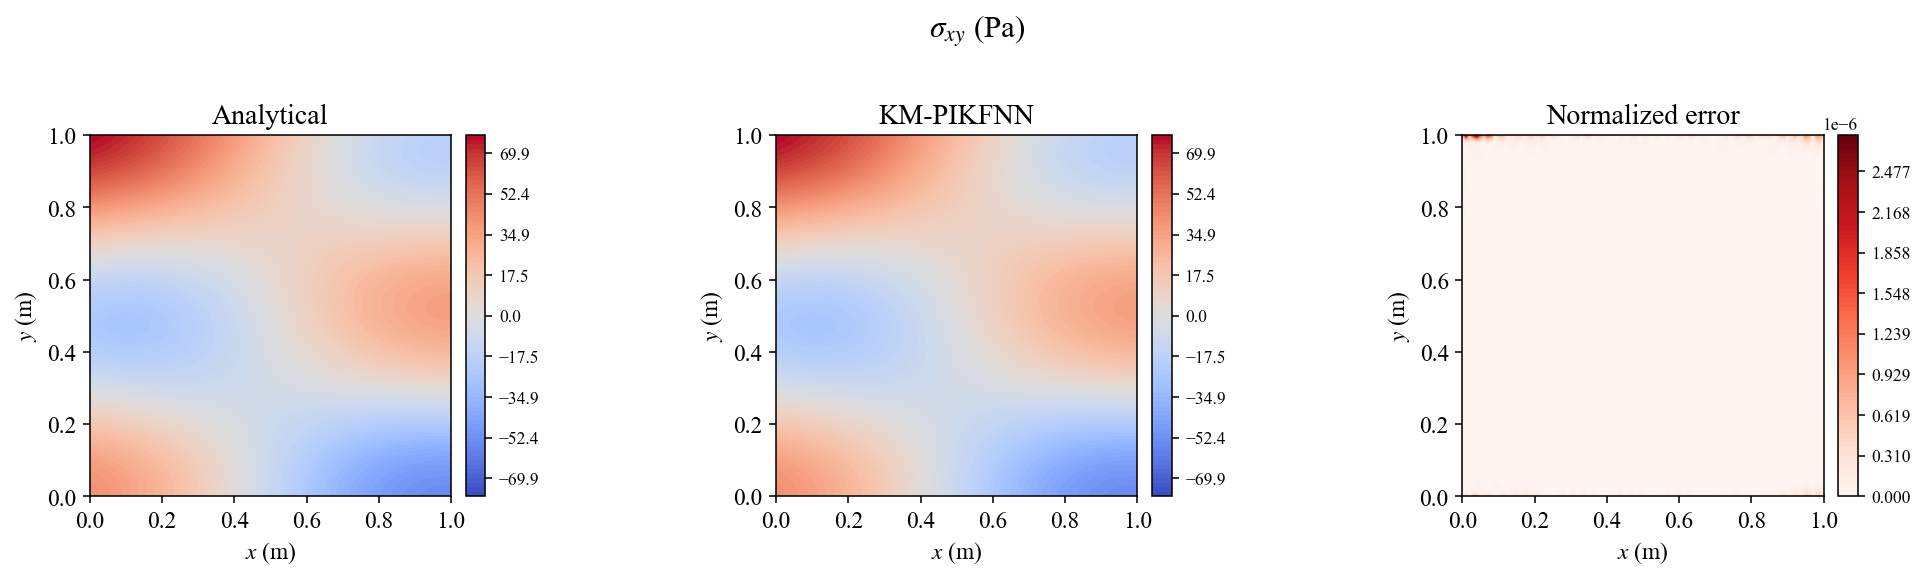

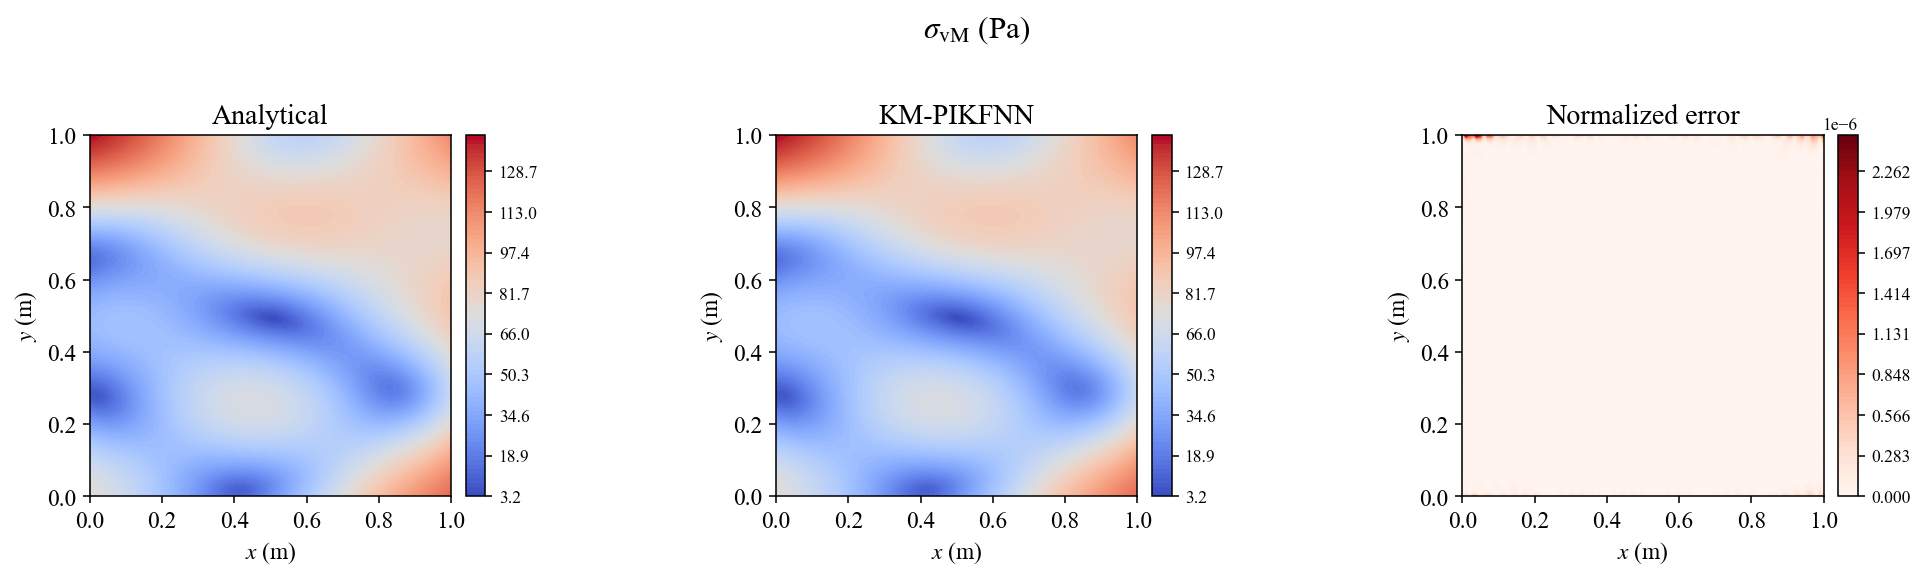

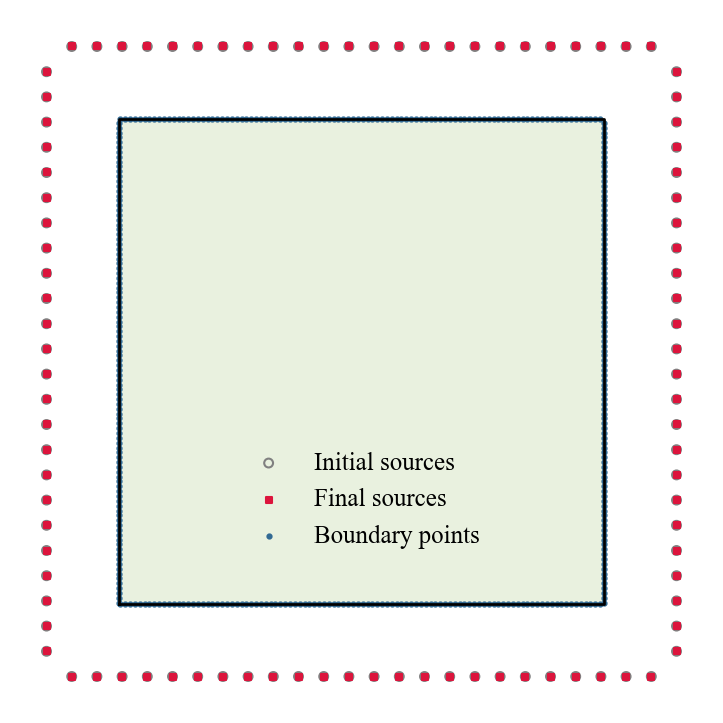

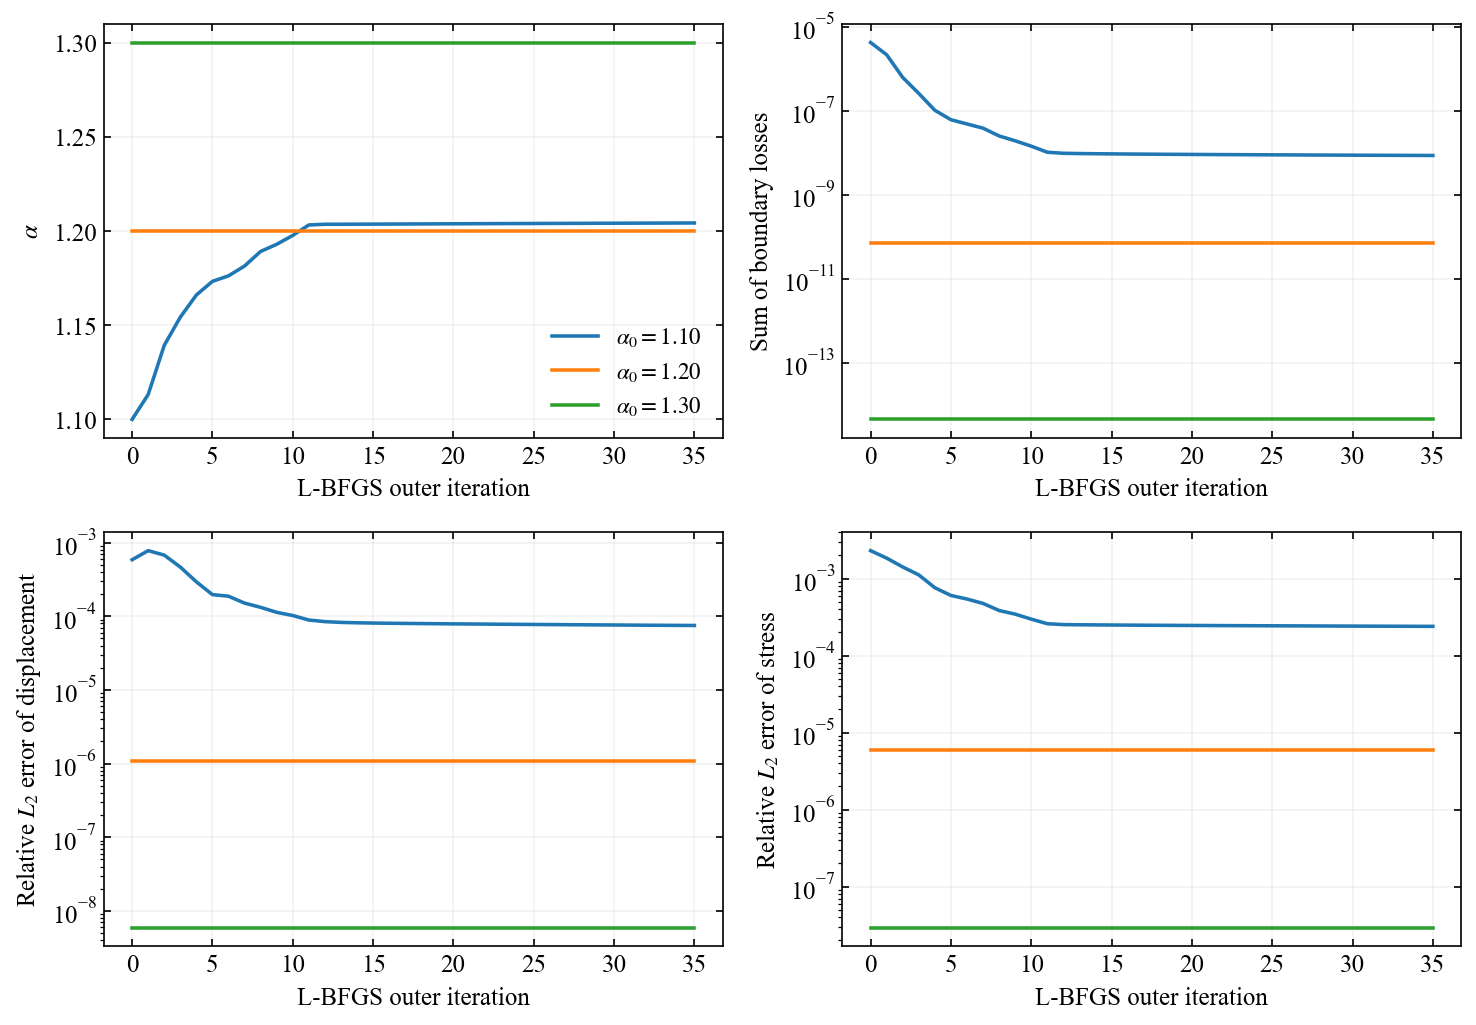

In [4]:
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['Times New Roman', 'DejaVu Serif'],
                     'mathtext.fontset': 'stix', 'font.size': 12})
def savefig(fig, name):
    if cfg['save_outputs']:
        folder = Path(cfg['output_dir']); folder.mkdir(parents=True, exist_ok=True)
        fig.savefig(folder/name, dpi=300, bbox_inches='tight')

# Six quantities: exact, predicted, pointwise normalized absolute error.
for i, (name, label) in enumerate(zip(quantities, labels)):
    ref = reference_real[:, i].reshape(X.shape)
    pred = prediction_real[:, i].reshape(X.shape)
    error = abs(pred-ref)/max(float(np.max(abs(ref))), 1e-30)
    vmin, vmax = min(ref.min(), pred.min()), max(ref.max(), pred.max())
    if i < 5:
        vmax = max(abs(vmin), abs(vmax)); vmin = -vmax
    levels = np.linspace(vmin, vmax, 81)
    fig, axes = plt.subplots(1, 3, figsize=(14.4, 4.5), dpi=140)
    fig.subplots_adjust(left=.06, right=.92, bottom=.15, top=.85, wspace=.90)
    for j, (ax, values, title) in enumerate(zip(axes, (ref, pred, error),
                                 ('Analytical', 'KM-PIKFNN', 'Normalized error'))):
        if j < 2:
            im = ax.contourf(L*X, L*Y, values, levels=levels, cmap='coolwarm', extend='both')
        else:
            im = ax.contourf(L*X, L*Y, values, levels=np.linspace(0, max(error.max(), 1e-16), 81), cmap='Reds')
        ax.set_aspect('equal', adjustable='box')
        ax.set_title(title); ax.set_xlabel(r'$x$ (m)'); ax.set_ylabel(r'$y$ (m)')
        cax = ax.inset_axes([1.04, 0, .055, 1])
        cb = fig.colorbar(im, cax=cax, extendrect=True, extendfrac=0)
        cb.formatter.set_powerlimits((-3, 3)); cb.update_ticks()
        cb.ax.tick_params(labelsize=9)
        cb.ax.yaxis.get_offset_text().set_fontsize(9)
    fig.suptitle(label, fontsize=16)
    savefig(fig, f'{name}_comparison.png'); plt.show()

# Initial and final source distributions.
fig, ax = plt.subplots(figsize=(6, 6), dpi=150)
ax.fill([0,L,L,0], [0,0,L,L], color='#CFE1B8', alpha=.45)
ax.plot([0,L,L,0,0], [0,0,L,L,0], 'k-', lw=1.3)
with torch.no_grad():
    initial_s = (0.5+0.5j)+best_run['alpha0']*model.base.cpu().numpy()
    final_s = model.sources().cpu().numpy()
ax.scatter(L*initial_s.real,L*initial_s.imag,s=18,facecolors='none',edgecolors='gray',label='Initial sources')
ax.scatter(L*final_s.real,L*final_s.imag,s=11,c='crimson',marker='s',label='Final sources')
bnd = np.concatenate([z.cpu().numpy() for z in train_points.values()])
ax.scatter(L*bnd.real,L*bnd.imag,s=4,c='#326A93',label='Boundary points')
ax.set_aspect('equal');ax.set_axis_off()
ax.legend(loc='center',bbox_to_anchor=(.5,.30),frameon=False,fontsize=12)
savefig(fig,'source_distribution.png');plt.show()

# One record is one L-BFGS OUTER step, not one closure/function evaluation.
fig, axes = plt.subplots(2,2,figsize=(10,7),dpi=150)
for run in runs:
    h = run['history']; it = [r['iteration'] for r in h]
    label = rf"$\alpha_0={run['alpha0']:.2f}$"
    for ax, key in zip(axes.ravel(), ('alpha','boundary_loss','displacement_L2','stress_L2')):
        values = [max(r[key],1e-30) for r in h]
        ax.plot(it,values,lw=1.7,label=label)
        if key != 'alpha':ax.set_yscale('log')
for ax, ylabel in zip(axes.ravel(), (r'$\alpha$', 'Sum of boundary losses',
                            r'Relative $L_2$ error of displacement', r'Relative $L_2$ error of stress')):
    ax.set_xlabel('L-BFGS outer iteration');ax.set_ylabel(ylabel)
    ax.tick_params(direction='in',top=True,right=True);ax.grid(alpha=.16)
axes[0,0].legend(loc='lower right',frameon=False,fontsize=11)
fig.tight_layout();savefig(fig,'optimization_histories.png');plt.show()

if cfg['save_outputs']:
    folder=Path(cfg['output_dir']);folder.mkdir(parents=True,exist_ok=True)
    for filename, rows in [('field_errors.csv',error_table),
             ('run_summary.csv',[dict(alpha_initial=r['alpha0'],alpha_final=r['model'].alpha().item(),
                  held_out_loss=r['check_loss'],elapsed_seconds=r['elapsed'],
                  initialization_seconds=r['initialization_time']) for r in runs])]:
        with (folder/filename).open('w',newline='',encoding='utf-8-sig') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(rows[0]));writer.writeheader();writer.writerows(rows)
    for run in runs:
        with (folder/f"history_alpha{run['alpha0']:.2f}.csv").open('w',newline='',encoding='utf-8-sig') as stream:
            writer=csv.DictWriter(stream,fieldnames=list(run['history'][0]));writer.writeheader();writer.writerows(run['history'])
    np.savez(folder/'fields_and_coefficients.npz',X=L*X,Y=L*Y,
             prediction=prediction_real,reference=reference_real,quantities=np.array(quantities),
             coefficients=(model.theta/model.column_scale).detach().cpu().numpy(),
             sources=L*final_s,alpha=model.alpha().item(),body_force=F_ref*body_force_fields(plot_z).detach().cpu().numpy())
